# 01 · Análise exploratória — manutenção preditiva

**Objetivo:** avaliar qualidade, distribuições, desbalanceamento e hipóteses para
futura modelagem. Nenhum classificador é treinado aqui. As saídas são calculadas
a partir do CSV local e persistidas em relatórios por execução.


## 1. Contrato do problema e limites

- **Unidade:** observação operacional; cada linha não identifica necessariamente
  uma máquina física independente.
- **Alvo:** `Machine failure`; positivo `1` = falha registrada naquela observação.
- **Momento pretendido:** sensores disponíveis antes da decisão de manutenção.
  O CSV não comprova antecedência nem fornece horizonte futuro ou datas.
  A classificação do estado de falha não demonstra antecipação de falha futura.
- **População:** registros locais; aplicação industrial real não validada.
- **Origem provável:** schema compatível com AI4I 2020, base sintética descrita pela
  [UCI](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset).
  A identidade byte a byte com a distribuição oficial não foi verificada.
- **Métrica futura proposta:** Average Precision (AP) para ordenação, complementada
  por Recall, Precision e F1. Custos de erros e capacidade de alertas estão em aberto.
- **Vazamento:** TWF/HDF/PWF/OSF/RNF são rótulos auxiliares, excluídos dos preditores.
  UDI e Product ID também ficam fora das entradas de futuros modelos.


In [1]:
from pathlib import Path
import sys
import json
import platform
import importlib.metadata
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'configs/data.json').is_file() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.data import load_config, load_data, development_split, sha256
from predictive_maintenance.eda import quality_table, outlier_table, outcome_rates

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {0: '#3977a8', 1: '#d96540'}
config = load_config(ROOT)
TARGET = config['target']
NUM = config['numeric_features']
FEATURES = NUM + config['categorical_features']
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:8]
FIGURES = ROOT / 'reports/figures' / RUN_ID
TABLES = ROOT / 'reports/metrics' / RUN_ID
EXPERIMENT = ROOT / 'reports/experiments' / RUN_ID
for path in (FIGURES, TABLES, EXPERIMENT):
    path.mkdir(parents=True, exist_ok=False)

def save_table(table, name):
    table.to_csv(TABLES / f'{name}.csv', encoding='utf-8', index=True)
    display(table)

def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'Execução: {RUN_ID} | Python {platform.python_version()}')


Execução: 20261031T002852Z_aa8e0ca3 | Python 3.12.14


## 2. Schema e reserva de TEST

Reservar o bloco final na ordem UDI, sem embaralhar, é uma escolha inicial
conservadora para sinais sequenciais. **UDI não é timestamp.** A fração 80/20
deixa a maior parte para investigação e 2.000 registros reservados no arquivo
atual; não foi escolhida por desempenho ou prevalência de TEST.

Sem horizonte ou duração conhecida da dependência, não há gap. Revisar divisão,
gap e validação por blocos antes da modelagem; não adotar CV aleatória por padrão.
A leitura global valida apenas o schema. Todas as distribuições e relações abaixo
usam **TRAIN**. TEST não é explorado.


In [2]:
raw = load_data(ROOT, config)
train, reserved_test = development_split(raw, config)
split = pd.concat([
    train[['UDI']].assign(partition='TRAIN'),
    reserved_test[['UDI']].assign(partition='TEST'),
], ignore_index=True)
split.to_csv(EXPERIMENT / 'split_membership.csv', index=False)
summary = pd.DataFrame({
    'conjunto': ['CSV completo (somente estrutura)', 'TRAIN explorado', 'TEST reservado'],
    'linhas': [len(raw), len(train), len(reserved_test)],
    'colunas': [raw.shape[1], train.shape[1], reserved_test.shape[1]],
}).set_index('conjunto')
save_table(summary, 'partition_sizes')
dataset_hash = sha256(ROOT / config['source'])
print('SHA256 do CSV:', dataset_hash)
del raw, reserved_test  # Evitar exploração acidental do TEST.


,linhas,colunas
conjunto,,
CSV completo (somente estrutura),10000,14
TRAIN explorado,8000,14
TEST reservado,2000,14


SHA256 do CSV: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


## 3. Dicionário, tipos e disponibilidade

`Type` representa variante de qualidade L/M/H. Os modos representam desgaste,
dissipação térmica, potência, sobrecarga e falha aleatória; servem somente à
auditoria dos rótulos. A disponibilidade dos sensores antes da decisão precisa
ser confirmada para uma aplicação real.


In [3]:
dictionary = pd.read_csv(ROOT / 'docs/data_dictionary.csv').set_index('feature')
save_table(dictionary.join(quality_table(train)), 'data_dictionary_and_quality')
display(train[FEATURES + [TARGET]].head(8))


,description,unit,role,available_before_decision,dtype,missing,missing_fraction,unique
feature,,,,,,,,
UDI,Identificador da ordem do registro,sem unidade,identificador excluído,não usar como sensor,int64,0,0.0,8000
Product ID,Identificador do produto com prefixo de qualidade,sem unidade,identificador excluído,entidade física não confirmada,object,0,0.0,8000
Type,Variante de qualidade L M ou H,categoria,preditor candidato,confirmar,object,0,0.0,3
Air temperature [K],Temperatura do ar,K,preditor candidato,confirmar,float64,0,0.0,93
Process temperature [K],Temperatura do processo,K,preditor candidato,confirmar,float64,0,0.0,82
Rotational speed [rpm],Velocidade de rotação,rpm,preditor candidato,confirmar,int64,0,0.0,903
Torque [Nm],Torque,Nm,preditor candidato,confirmar,float64,0,0.0,568
Tool wear [min],Desgaste acumulado da ferramenta,min,preditor candidato,confirmar,int64,0,0.0,246
Machine failure,Falha: 0 ausente e 1 presente,binária,alvo,não,int64,0,0.0,2


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,Machine failure
0,298.1,308.6,1551,42.8,0,M,0
1,298.2,308.7,1408,46.3,3,L,0
2,298.1,308.5,1498,49.4,5,L,0
3,298.2,308.6,1433,39.5,7,L,0
4,298.2,308.7,1408,40.0,9,L,0
5,298.1,308.6,1425,41.9,11,M,0
6,298.1,308.6,1558,42.4,14,L,0
7,298.1,308.6,1527,40.2,16,L,0


## 4. Qualidade e plausibilidade

Duplicação de linhas completas, entradas e identificadores são conceitos distintos.
Entradas iguais com alvos diferentes merecem auditoria. Extremos de 1,5×IQR
sinalizam caudas; não são necessariamente erros e não serão removidos.
Limites físicos específicos da máquina não foram fornecidos.


In [4]:
repeated = train.duplicated(FEATURES, keep=False)
contradictory = train.groupby(FEATURES, dropna=False)[TARGET].nunique().gt(1).sum()
checks = pd.Series({
    'linhas_duplicadas_completas': int(train.duplicated().sum()),
    'linhas_com_entradas_repetidas': int(repeated.sum()),
    'grupos_com_alvos_contraditorios': int(contradictory),
    'UDI_repetido': int(train['UDI'].duplicated().sum()),
    'Product_ID_repetido': int(train['Product ID'].duplicated().sum()),
    'celulas_ausentes': int(train.isna().sum().sum()),
    'processo_mais_frio_que_ar': int((train[NUM[1]] < train[NUM[0]]).sum()),
    'temperatura_absoluta_nao_positiva': int((train[NUM[:2]] <= 0).any(axis=1).sum()),
    'rotacao_nao_positiva': int((train['Rotational speed [rpm]'] <= 0).sum()),
    'tipo_diverge_prefixo': int(train['Product ID'].astype('string').str[0].ne(train['Type']).sum()),
}, name='contagem').to_frame()
save_table(checks, 'quality_checks')
extremes = outlier_table(train, NUM)
save_table(extremes, 'outlier_flags')
save_table(train[NUM].describe().T, 'numeric_summary')
display(Markdown(f"**Leitura:** {checks.loc['celulas_ausentes', 'contagem']:,} células ausentes; "
    f"{int(extremes['flagged'].sum()):,} sinalizações IQR somadas entre variáveis "
    '(uma linha pode aparecer várias vezes). Nenhum registro foi removido.'))


,contagem
linhas_duplicadas_completas,0
linhas_com_entradas_repetidas,0
grupos_com_alvos_contraditorios,0
UDI_repetido,0
Product_ID_repetido,0
celulas_ausentes,0
processo_mais_frio_que_ar,0
temperatura_absoluta_nao_positiva,0
rotacao_nao_positiva,0
tipo_diverge_prefixo,0


,lower_iqr,upper_iqr,flagged,negative
feature,,,,
Air temperature [K],294.4000,306.4000,0,0
Process temperature [K],305.8875,314.3875,5,0
Rotational speed [rpm],1137.3750,1898.3750,348,0
Torque [Nm],12.7375,67.2375,57,0
Tool wear [min],-112.0000,328.0000,0,0


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],8000.0,300.405650,1.998787,295.3,298.900,300.6,301.9,304.5
Process temperature [K],8000.0,310.158175,1.535774,305.7,309.075,310.4,311.2,313.8
Rotational speed [rpm],8000.0,1539.846875,182.600323,1168.0,1422.750,1503.0,1613.0,2886.0
Torque [Nm],8000.0,39.977438,10.046327,3.8,33.175,40.1,46.8,76.6
Tool wear [min],8000.0,108.377250,63.782729,0.0,53.000,108.0,163.0,253.0


**Leitura:** 0 células ausentes; 410 sinalizações IQR somadas entre variáveis (uma linha pode aparecer várias vezes). Nenhum registro foi removido.

### 4.1. Consistência dos rótulos

A união dos modos deveria ser confrontada com a definição do alvo. Divergências
não serão corrigidas automaticamente. Os modos podem coexistir: suas contagens
não devem ser somadas como falhas distintas.


In [5]:
any_mode = train[config['failure_modes']].eq(1).any(axis=1)
audit = pd.crosstab(train[TARGET].rename('Machine failure'), any_mode.rename('algum_modo_ativo'))
save_table(audit, 'label_consistency')
save_table(train[config['failure_modes']].sum().rename('ocorrencias').to_frame(), 'failure_modes_train')
mismatches = int(any_mode.ne(train[TARGET].eq(1)).sum())
display(Markdown(f'**Leitura:** {mismatches} registros de TRAIN divergem entre alvo e '
                 'união dos modos. Confirmar origem e política de anotação antes de corrigir.'))


algum_modo_ativo,False,True
Machine failure,,
0,7682,18
1,7,293


,ocorrencias
TWF,36
HDF,115
PWF,85
OSF,77
RNF,19


**Leitura:** 25 registros de TRAIN divergem entre alvo e união dos modos. Confirmar origem e política de anotação antes de corrigir.

## 5. Desbalanceamento do alvo

O denominador é o número de observações em TRAIN. Acurácia isolada pode ocultar
falhas perdidas; ainda não há avaliação de classificador.


,n,fraction
Machine failure,,
0,7700,0.9625
1,300,0.0375


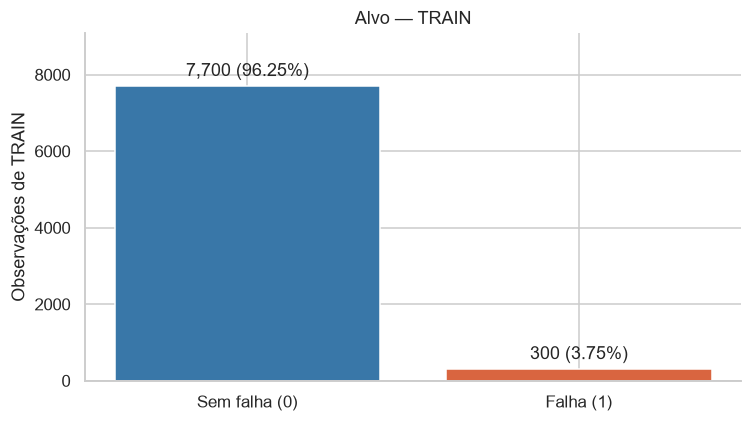

**Leitura:** prevalência em TRAIN = **3.75%**. Considerar AP, Recall e Precision na futura modelagem.

In [6]:
counts = train[TARGET].value_counts().reindex([0, 1], fill_value=0)
classes = counts.rename('n').to_frame()
classes['fraction'] = classes['n'] / len(train)
save_table(classes, 'target_distribution')
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Sem falha (0)', 'Falha (1)'], counts, color=[COLORS[0], COLORS[1]])
ax.bar_label(bars, labels=[f'{n:,} ({n / len(train):.2%})' for n in counts], padding=4)
ax.set(ylabel='Observações de TRAIN', title='Alvo — TRAIN', ylim=(0, counts.max()*1.18))
finish_figure(fig, 'target_distribution')
prevalence = float(train[TARGET].mean())
display(Markdown(f'**Leitura:** prevalência em TRAIN = **{prevalence:.2%}**. '
                 'Considerar AP, Recall e Precision na futura modelagem.'))


## 6. Distribuições dos sensores

As densidades são normalizadas por classe para comparar forma, sem representar
a prevalência populacional. Boxplots mostram quartis e extremos, sem exclusões.


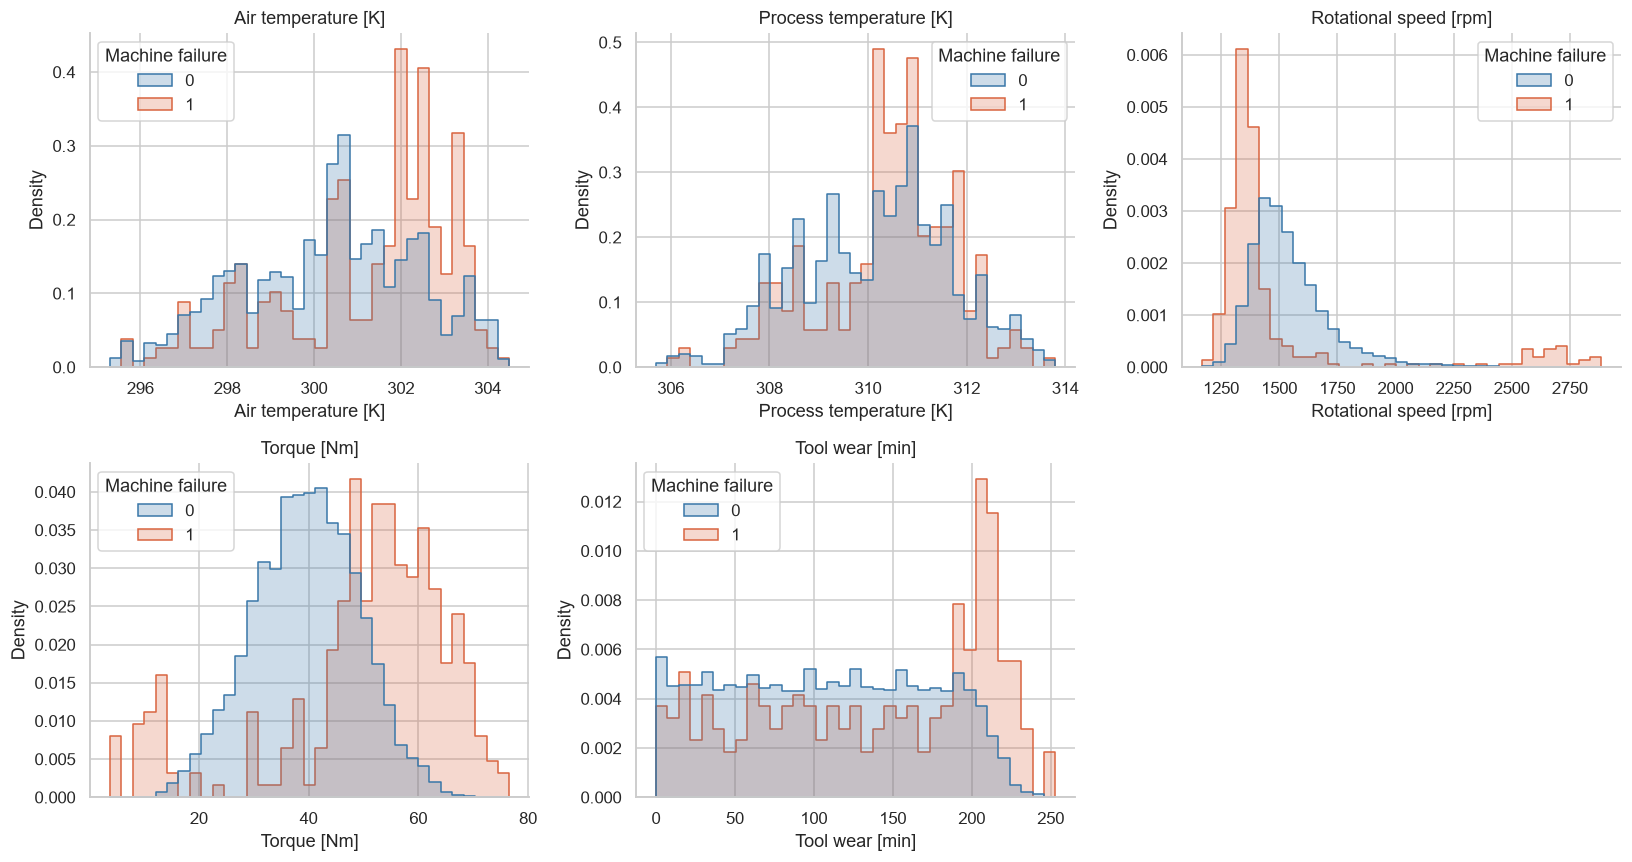

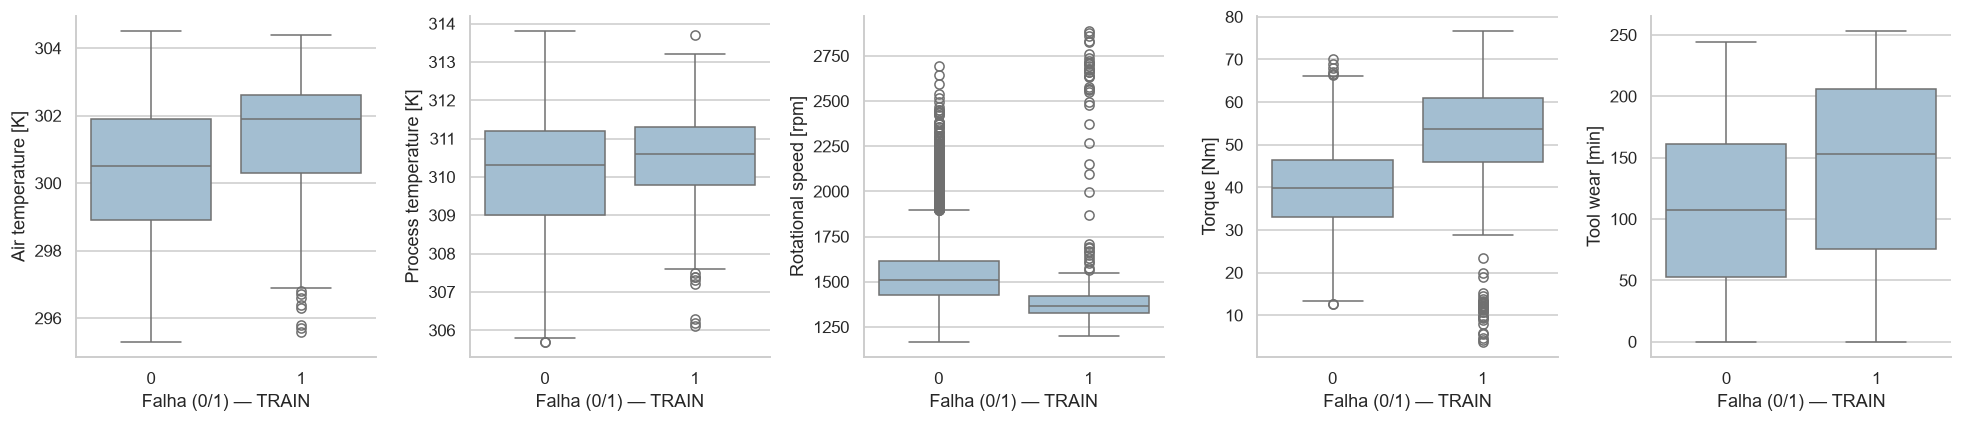

Machine failure,0,1
Air temperature [K],300.5,301.9
Process temperature [K],310.3,310.6
Rotational speed [rpm],1507.0,1363.5
Torque [Nm],39.8,53.6
Tool wear [min],107.0,153.0


**Leitura:** compare medianas e caudas na tabela acima. A sobreposição das classes impede inferir uma separação perfeita a partir de um único sensor; diferenças descritivas não medem desempenho fora da amostra.

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(NUM, axes.flat):
    sns.histplot(data=train, x=feature, hue=TARGET, hue_order=[0, 1],
                 palette=COLORS, bins=35, stat='density', common_norm=False,
                 element='step', ax=ax)
    ax.set_title(feature)
axes.flat[-1].set_visible(False)
finish_figure(fig, 'sensor_distributions_by_target')
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for feature, ax in zip(NUM, axes):
    sns.boxplot(data=train, x=TARGET, y=feature, color='#9bc0d9', ax=ax)
    ax.set_xlabel('Falha (0/1) — TRAIN')
finish_figure(fig, 'sensor_boxplots')
medians = train.groupby(TARGET)[NUM].median().T
save_table(medians, 'sensor_medians_by_class')
display(Markdown('**Leitura:** compare medianas e caudas na tabela acima. '
    'A sobreposição das classes impede inferir uma separação perfeita a partir '
    'de um único sensor; diferenças descritivas não medem desempenho fora da amostra.'))


## 7. Taxas por categoria e faixas

Taxa = falhas / observações do grupo. Exibir denominadores para não interpretar
grupos pequenos como padrões estáveis. Quantis são aprendidos só em TRAIN,
para exploração; em modelagem, aprender faixas dentro dos folds.


,n,failures,failure_rate,non_failures
Type,,,,
H,782,21,0.026854,761
L,4816,203,0.042151,4613
M,2402,76,0.031640,2326


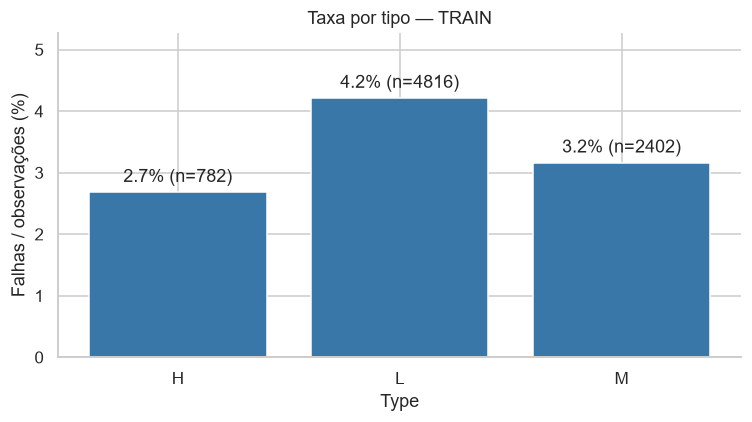

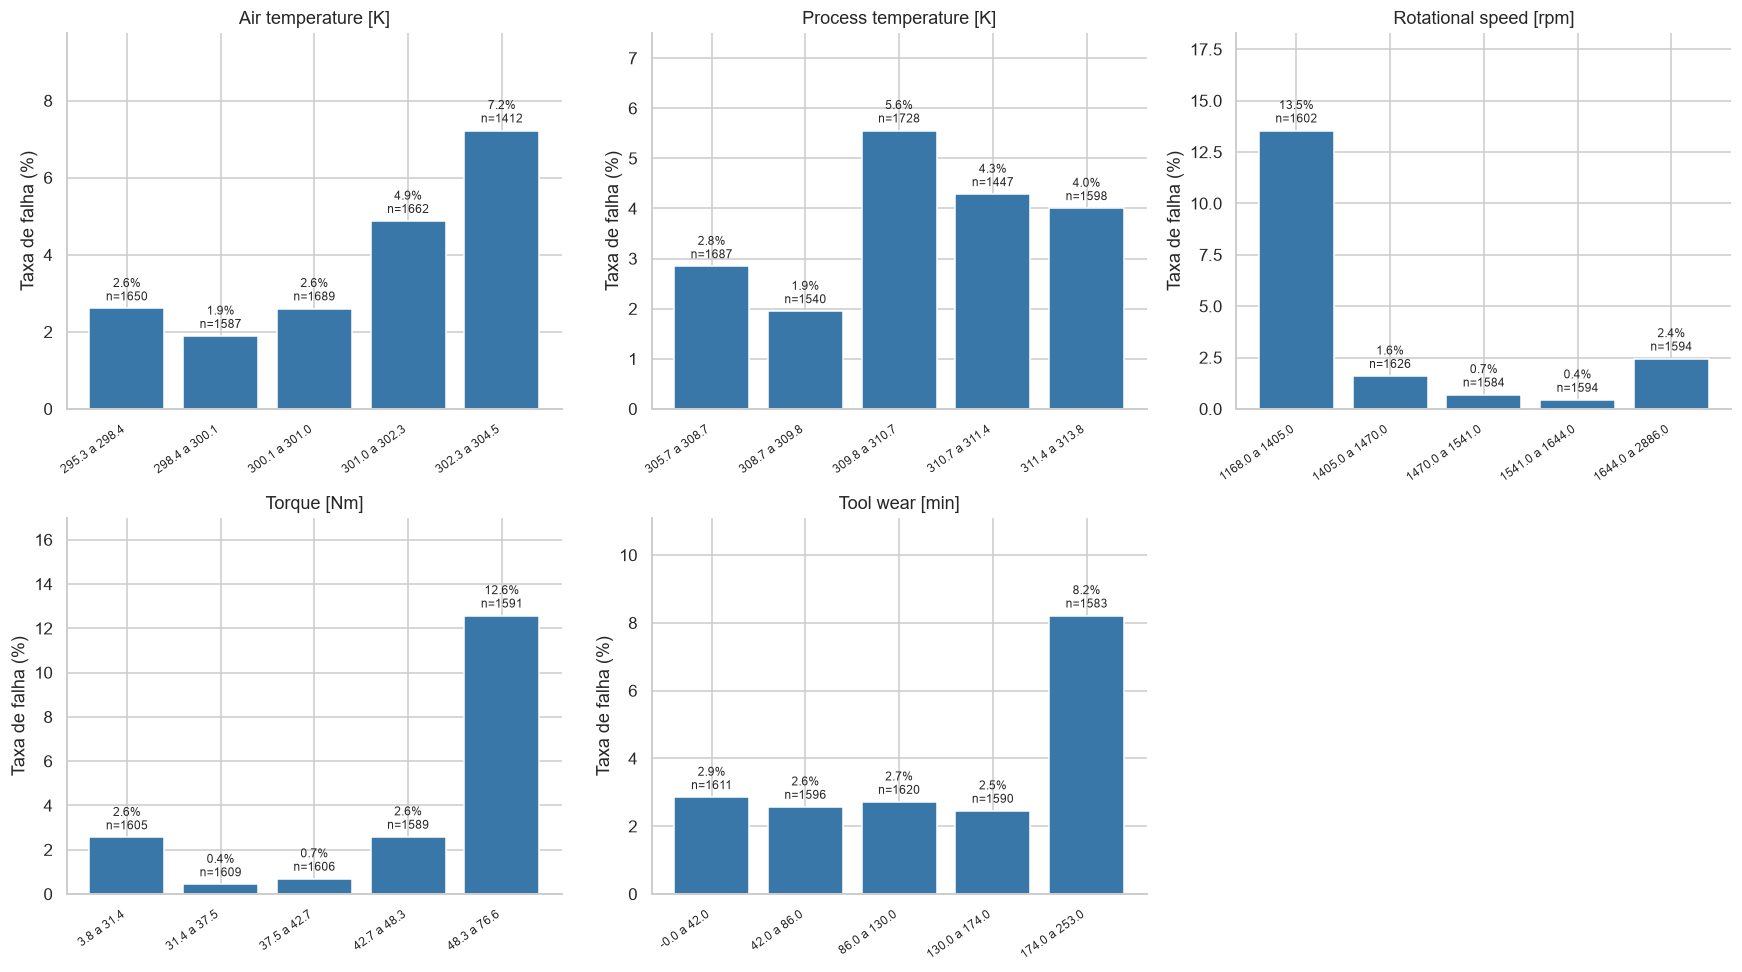

,faixa,n,failures,failure_rate,non_failures,feature
0,"(295.29900000000004, 298.4]",1650,43,0.026061,1607,Air temperature [K]
1,"(298.4, 300.1]",1587,30,0.018904,1557,Air temperature [K]
2,"(300.1, 301.0]",1689,44,0.026051,1645,Air temperature [K]
3,"(301.0, 302.3]",1662,81,0.048736,1581,Air temperature [K]
4,"(302.3, 304.5]",1412,102,0.072238,1310,Air temperature [K]
5,"(305.699, 308.7]",1687,48,0.028453,1639,Process temperature [K]
6,"(308.7, 309.8]",1540,30,0.019481,1510,Process temperature [K]
7,"(309.8, 310.7]",1728,96,0.055556,1632,Process temperature [K]
8,"(310.7, 311.4]",1447,62,0.042847,1385,Process temperature [K]
9,"(311.4, 313.8]",1598,64,0.040050,1534,Process temperature [K]


**Leitura:** rótulos das faixas arredondados para uma casa; intervalos exatos estão na tabela. Variação nas taxas sugere hipóteses de associação e não regras causais. As mesmas observações aparecem em cada feature: não somar denominadores entre variáveis.

In [8]:
type_rates = outcome_rates(train, 'Type', TARGET)
save_table(type_rates, 'rates_by_type')
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(type_rates.index.astype(str), type_rates['failure_rate'] * 100, color='#3977a8')
ax.bar_label(bars, labels=[f'{r.failure_rate:.1%} (n={r.n})' for r in type_rates.itertuples()], padding=4)
ax.set(xlabel='Type', ylabel='Falhas / observações (%)', title='Taxa por tipo — TRAIN')
ax.margins(y=0.25)
finish_figure(fig, 'rates_by_type')

rate_tables = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for feature, ax in zip(NUM, axes.flat):
    bins = pd.qcut(train[feature], q=5, duplicates='drop')
    local = train.assign(faixa=bins if bins.notna().any() else 'constante/ausente')
    rates = outcome_rates(local, 'faixa', TARGET)
    rate_tables.append(rates.reset_index().assign(feature=feature))
    bars = ax.bar(np.arange(len(rates)), rates['failure_rate'] * 100, color='#3977a8')
    ax.bar_label(bars, labels=[f'{r.failure_rate:.1%}\nn={r.n}' for r in rates.itertuples()], fontsize=8, padding=3)
    labels = [f'{v.left:.1f} a {v.right:.1f}' if isinstance(v, pd.Interval) else str(v) for v in rates.index]
    ax.set_xticks(np.arange(len(rates)), labels, rotation=35, ha='right', fontsize=8)
    ax.set(title=feature, ylabel='Taxa de falha (%)')
    ax.margins(y=0.35)
axes.flat[-1].set_visible(False)
finish_figure(fig, 'rates_by_numeric_bins')
save_table(pd.concat(rate_tables, ignore_index=True), 'rates_by_numeric_bins')
display(Markdown('**Leitura:** rótulos das faixas arredondados para uma casa; '
    'intervalos exatos estão na tabela. Variação nas taxas sugere hipóteses de '
    'associação e não regras causais. As mesmas observações aparecem em cada '
    'feature: não somar denominadores entre variáveis.'))


## 8. Associações e redundância — TRAIN

Pearson mede associação linear; Spearman, monotônica. Com alvo binário, Pearson
é ponto-bisserial. `Type` não recebe código numérico arbitrário. Relações fracas
não descartam interações, e associação não demonstra causalidade.

**Associação versus importância:** os painéis comparam duas associações.
Importância preditiva fica adiada porque requer modelo e validação. Quando houver
modelo, comparar associação com permutation importance em validação interna de TRAIN,
em painéis alinhados. Correlação não substitui importância.


,pearson,spearman
Process temperature [K],0.030568,0.032779
Air temperature [K],0.078712,0.086602
Tool wear [min],0.093256,0.089695
Rotational speed [rpm],-0.043274,-0.178894
Torque [Nm],0.197213,0.178934


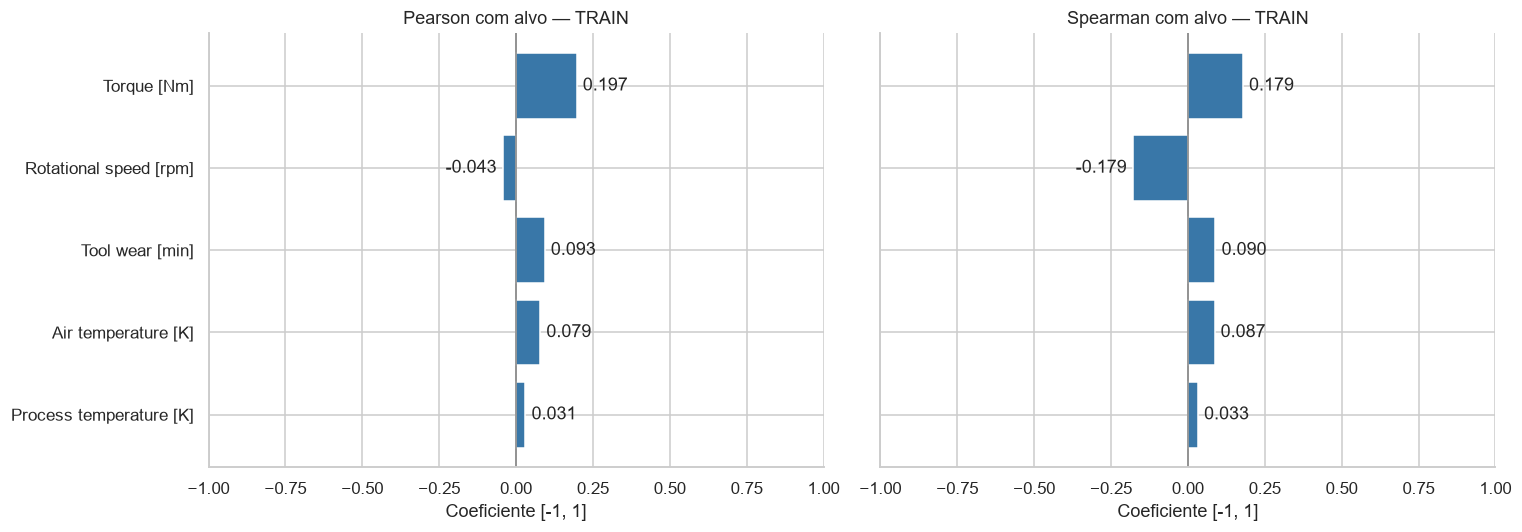

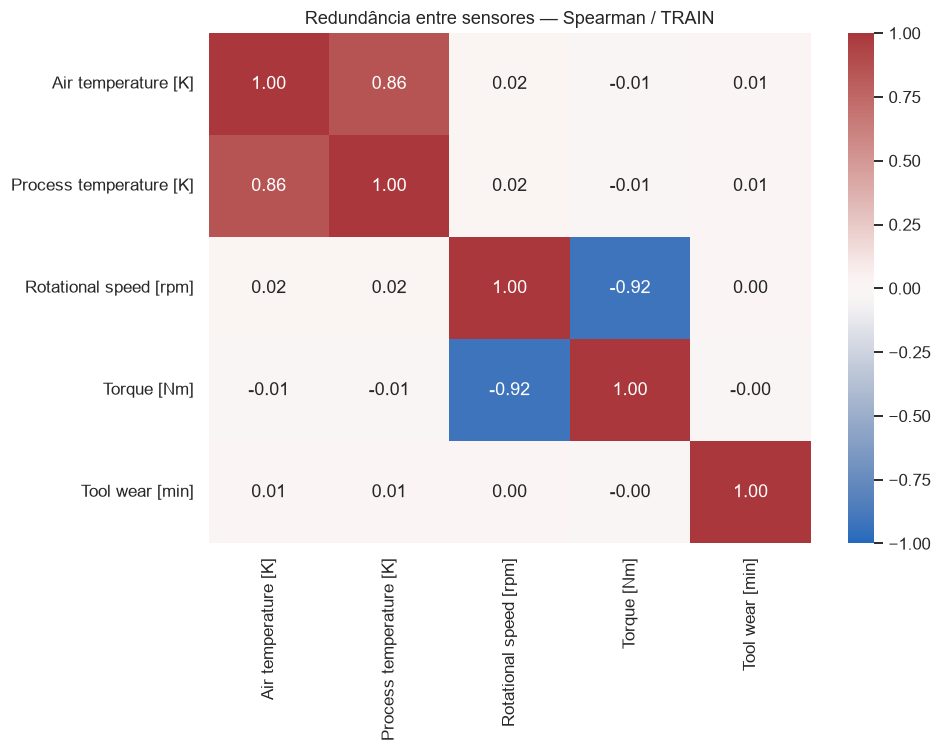

**Leitura:** maior associação monotônica em módulo: `Torque [Nm]` (0.179). Isso não determina utilidade preditiva nem seleção automática.

In [9]:
association = pd.DataFrame({
    'pearson': train[NUM + [TARGET]].corr(method='pearson')[TARGET].drop(TARGET),
    'spearman': train[NUM + [TARGET]].corr(method='spearman')[TARGET].drop(TARGET),
}).sort_values('spearman', key=lambda s: s.abs())
save_table(association, 'feature_target_associations')
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for method, ax in zip(association.columns, axes):
    bars = ax.barh(association.index, association[method], color='#3977a8')
    ax.bar_label(bars, fmt='%.3f', padding=4)
    ax.axvline(0, color='gray', linewidth=1)
    ax.set(title=f'{method.title()} com alvo — TRAIN', xlabel='Coeficiente [-1, 1]', xlim=(-1, 1))
finish_figure(fig, 'target_associations')
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train[NUM].corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag',
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Redundância entre sensores — Spearman / TRAIN')
finish_figure(fig, 'sensor_correlation')
strongest = association['spearman'].abs().idxmax()
display(Markdown(f'**Leitura:** maior associação monotônica em módulo: `{strongest}` '
                 f'({association.loc[strongest, "spearman"]:.3f}). '
                 'Isso não determina utilidade preditiva nem seleção automática.'))


## 9. Interações e ordem dos registros

Investigar regimes de torque/rotação e diferença térmica. Eles podem refletir
mecanismos sintéticos. UDI indica ordem de registro, **não tempo transcorrido**.
Blocos são descritivos; não são folds ou janelas temporais já validados.


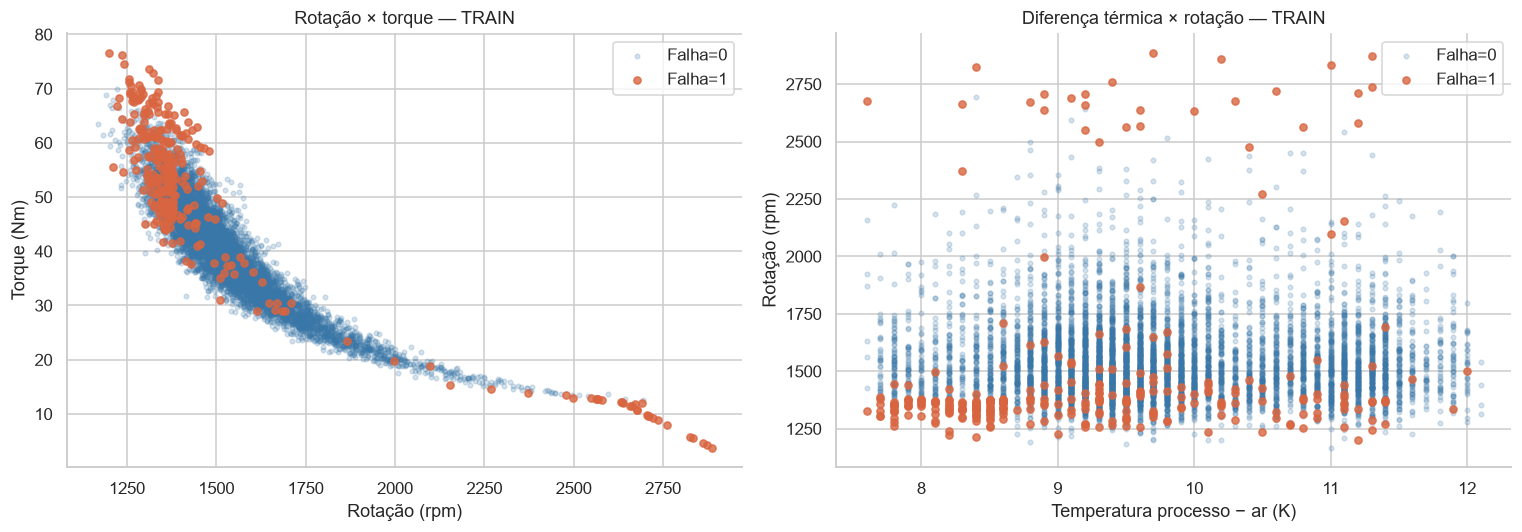

,n,failures,failure_rate,non_failures
bloco,,,,
1,500,16,0.032,484
2,500,7,0.014,493
3,500,19,0.038,481
4,500,10,0.020,490
5,500,12,0.024,488
6,500,10,0.020,490
7,500,9,0.018,491
8,500,18,0.036,482
9,500,76,0.152,424


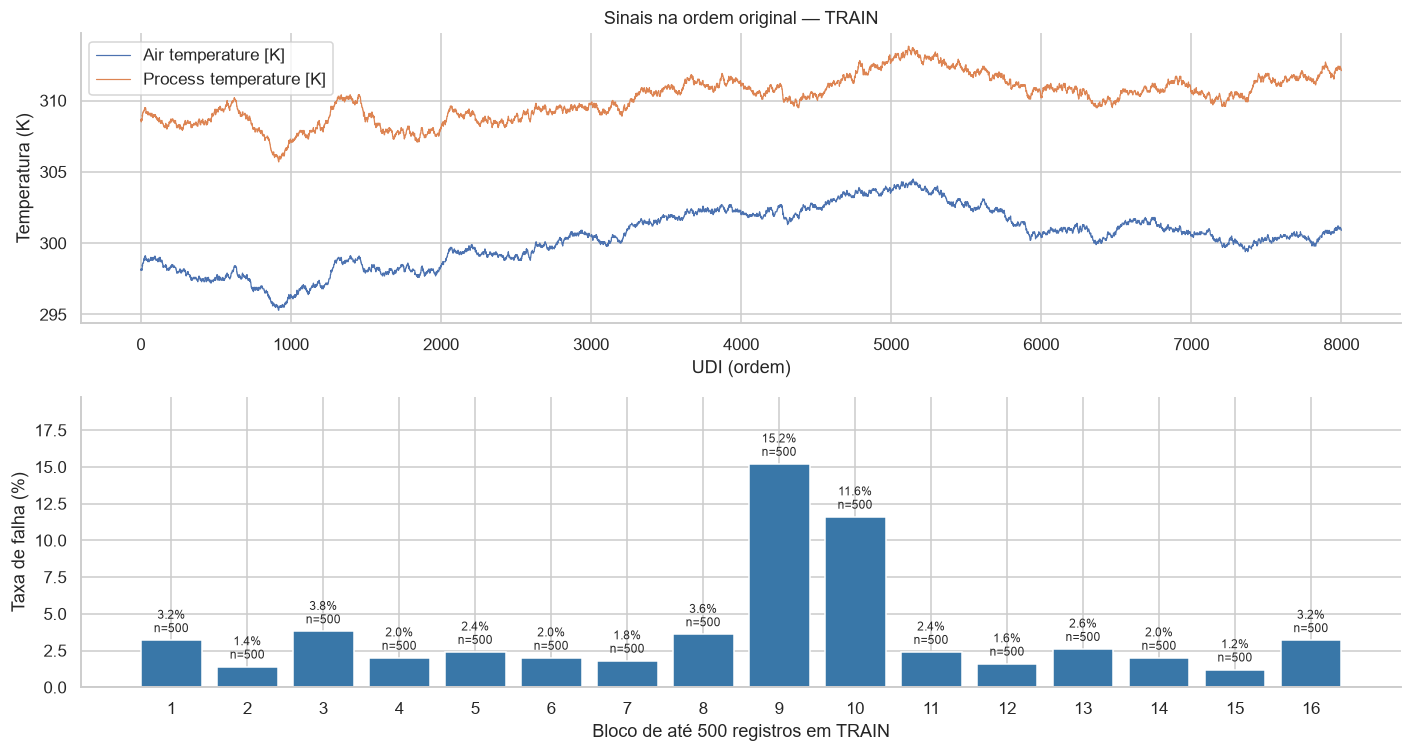

In [10]:
derived = train.assign(temperature_gap_K=train[NUM[1]] - train[NUM[0]])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label in (0, 1):
    group = derived.loc[derived[TARGET].eq(label)]
    axes[0].scatter(group['Rotational speed [rpm]'], group['Torque [Nm]'],
                    s=9 if label == 0 else 22, alpha=0.2 if label == 0 else 0.8,
                    color=COLORS[label], label=f'Falha={label}')
    axes[1].scatter(group['temperature_gap_K'], group['Rotational speed [rpm]'],
                    s=9 if label == 0 else 22, alpha=0.2 if label == 0 else 0.8,
                    color=COLORS[label], label=f'Falha={label}')
axes[0].set(xlabel='Rotação (rpm)', ylabel='Torque (Nm)', title='Rotação × torque — TRAIN')
axes[1].set(xlabel='Temperatura processo − ar (K)', ylabel='Rotação (rpm)', title='Diferença térmica × rotação — TRAIN')
for ax in axes:
    ax.legend()
finish_figure(fig, 'sensor_interactions')

ordered = train.sort_values('UDI').assign(bloco=lambda d: np.arange(len(d)) // 500 + 1)
block_rates = outcome_rates(ordered, 'bloco', TARGET)
save_table(block_rates, 'rates_by_record_block')
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for feature in NUM[:2]:
    axes[0].plot(ordered['UDI'], ordered[feature], linewidth=0.8, label=feature)
axes[0].set(xlabel='UDI (ordem)', ylabel='Temperatura (K)', title='Sinais na ordem original — TRAIN')
axes[0].legend()
bars = axes[1].bar(block_rates.index.astype(str), block_rates['failure_rate'] * 100, color='#3977a8')
axes[1].bar_label(bars, labels=[f'{r.failure_rate:.1%}\nn={r.n}' for r in block_rates.itertuples()], fontsize=8, padding=3)
axes[1].set(xlabel='Bloco de até 500 registros em TRAIN', ylabel='Taxa de falha (%)')
axes[1].margins(y=0.3)
finish_figure(fig, 'ordered_signal_and_block_rates')


## 10. Síntese para revisão e proveniência

As conclusões são calculadas em TRAIN. Definição do problema e protocolo
precisam ser revisados antes de modelar e acessar o conjunto reservado.


In [11]:
findings = f"""
- TRAIN contém **{len(train):,} observações** e **{int(train[TARGET].sum()):,} falhas ({prevalence:.2%})**.
- **{int(train.isna().sum().sum())} células ausentes** e **{int(train.duplicated(FEATURES).sum())} entradas duplicadas** além da primeira ocorrência.
- **{mismatches} divergências de rótulo** entre alvo e união dos modos; sem correções automáticas.
- **{int(extremes['flagged'].sum())} sinalizações IQR** somadas entre variáveis; nenhum registro removido.
- Maior associação Spearman em módulo: **{strongest}**; investigar interações antes de seleção.
- TEST permanece reservado. Nenhum modelo, threshold ou importance foi ajustado.

**Próximas decisões:** confirmar antecedência dos sensores, horizonte e identidade
de equipamento; auditar rótulos; revisar blocos/gap; estabelecer baseline e pipeline
em TRAIN. AP é proposta para ordenação; Recall/Precision/F1 devem acompanhar custos
e capacidade de atender alertas. Sem avaliação de generalização nesta etapa.
"""
display(Markdown(findings))
(EXPERIMENT / 'findings.md').write_text(findings.strip() + '\n', encoding='utf-8')
versions = {name: importlib.metadata.version(name) for name in
            ['pandas', 'numpy', 'matplotlib', 'seaborn', 'nbformat', 'nbclient', 'ipykernel']}
manifest = {
    'run_id': RUN_ID, 'dataset': config['source'], 'dataset_sha256': dataset_hash,
    'config': config, 'python': platform.python_version(), 'versions': versions,
    'train_rows': len(train), 'test_rows': int((split['partition'] == 'TEST').sum()),
    'explored_partition': 'TRAIN', 'models_fitted': False,
    'split_membership': 'split_membership.csv', 'randomness': 'nenhuma; operações determinísticas',
    'code_sha256': {str(p.relative_to(ROOT)): sha256(p) for p in [
        ROOT / 'scripts/create_eda_notebook.py', ROOT / 'scripts/execute_eda.py',
        *sorted((ROOT / 'src/predictive_maintenance').glob('*.py')),
    ]},
}
(EXPERIMENT / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Tabelas:', TABLES.relative_to(ROOT))
print('Figuras:', FIGURES.relative_to(ROOT))
print('Proveniência:', EXPERIMENT.relative_to(ROOT))



- TRAIN contém **8,000 observações** e **300 falhas (3.75%)**.
- **0 células ausentes** e **0 entradas duplicadas** além da primeira ocorrência.
- **25 divergências de rótulo** entre alvo e união dos modos; sem correções automáticas.
- **410 sinalizações IQR** somadas entre variáveis; nenhum registro removido.
- Maior associação Spearman em módulo: **Torque [Nm]**; investigar interações antes de seleção.
- TEST permanece reservado. Nenhum modelo, threshold ou importance foi ajustado.

**Próximas decisões:** confirmar antecedência dos sensores, horizonte e identidade
de equipamento; auditar rótulos; revisar blocos/gap; estabelecer baseline e pipeline
em TRAIN. AP é proposta para ordenação; Recall/Precision/F1 devem acompanhar custos
e capacidade de atender alertas. Sem avaliação de generalização nesta etapa.


Tabelas: reports\metrics\20261031T002852Z_aa8e0ca3
Figuras: reports\figures\20261031T002852Z_aa8e0ca3
Proveniência: reports\experiments\20261031T002852Z_aa8e0ca3
